In [1]:
import os
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from collections import defaultdict
import matplotlib.pyplot as plt
from typing import Optional

from dereko_search import get_dereko_matches

In [2]:
datadir = "../resources/developed"
sample_dir = os.path.join(datadir, "gecodb_v07_pll_300er_sample")
os.makedirs(sample_dir, exist_ok=True)

This script samples a portion of compounds that may insert a pluralic linker (PLL) for manual annotation. The annotated data will further be used for investigation of the internal plural effect (IntPE) as defined by Schäfer & Pankratz 2018.

The reason the script is formatted as a notebook is because a few distribution inspections and statistical tests are provisioned, and so an interactive and step-wise manner of sampling is preferred.

The sampling goes as follows:
1. Load GeCoDB_v07.
2. Keep only compounds whose N1s may attach the PLL.
3. Save the intermediate GeCoDB_v07_PLL dataset.
4. Filter out N1s that predominantly attach (N)PLLs.
5. Define the frequency class of the compounds.
6. Self-evaluation: make sure that the logarithmic frequency/productivity values are distributed identically to the labelled classes.
7. Sample up to 300 compounds pro PLL in a distribution-aware manner.
8. Self-evaluation: make sure that the distribution of the frequency classes of the whole population is identical to that of the sample.
9. Manual cleaning.
10. Extract contexts from DeReKo.
11. Format the dataset.
12. Save the dataset.

1. Load GeCoDB_v07.

In [3]:
# (N=277361)
gecodb_v07 = pd.read_csv(
    os.path.join(datadir, "gecodb_v07.tsv"),
    sep="\t",
    dtype=defaultdict(
        lambda: str,
        **{
            f"{prx}_freq": int
            for prx in ["comp", "n1", "n2"]
        },
        n1_prod="int",
        is_pll="bool",
        umlaut_applied="bool"
    ),
    header=0,
    index_col=0
)

gecodb_v07.sample(10)

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq
comp_gecodb,,,,,,,,,,
schiefer_griffel,Schiefergriffel,31,schiefer,18372,64,_,False,False,griffel,4616
insulin_wirkung,Insulinwirkung,145,insulin,18443,29,_,False,False,wirkung,593084
schraube_+n_baum,Schraubenbaum,89,schraube,20496,40,_+n_,True,False,baum,1443177
zuschauer_rang,Zuschauerrang,7763,zuschauer,1860392,184,_,False,False,rang,923686
unfall_reaktor,Unfallreaktor,42,unfall,1264412,191,_,False,False,reaktor,72943
kreisel_pumpe,Kreiselpumpe,244,kreisel,94850,25,_,False,False,pumpe,51311
präsidium_+s_team,Präsidiumsteam,31,präsidium,134542,25,_+s_,False,False,team,3704600
schein_antrag,Scheinantrag,99,schein,140759,182,_,False,False,antrag,1772915
zulassung_+s_zahl,Zulassungszahl,4890,zulassung,144722,105,_+s_,False,False,zahl,3730474


2. Keep only compounds whose N1s may attach the PLL.

    Since we want to study the alternation between the non-pluralic linkers (NPLLs) and PLLs, we keep all compounds with the resulting N1s both with NPLLs and PLLs.

In [4]:
# filter out N1s that may not attach pl linkers
gecodb_v07pll_n1s = gecodb_v07[gecodb_v07["is_pll"]]["n1_lemma"].unique()
gecodb_v07pll = gecodb_v07[gecodb_v07["n1_lemma"].isin(gecodb_v07pll_n1s)]

gecodb_v07pll.sample(10)

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq
comp_gecodb,,,,,,,,,,
gott_schall,Gottschall,2100,gott,973846,257,_,False,False,schall,38216
dame_+n_kopf,Damenkopf,72,dame,1577700,184,_+n_,True,False,kopf,1846720
geschäft_+s_erwartung,Geschäftserwartung,5189,geschäft,1891578,405,_+s_,False,False,erwartung,588945
grund_lohn,Grundlohn,1420,grund,4368447,605,_,False,False,lohn,401214
krise_+n_markt,Krisenmarkt,88,krise,1044198,270,_+n_,True,False,markt,2649376
meer_+es_ungeheuer,Meeresungeheuer,548,meer,540391,309,_+es_,False,False,ungeheuer,21014
sonne_+n_verlag,Sonnenverlag,20,sonne,829937,354,_+n_,True,False,verlag,649628
stand_meldung,Standmeldung,47,stand,1167927,233,_,False,False,meldung,368911
gesetz_+es_schreiber,Gesetzesschreiber,31,gesetz,1456035,199,_+es_,False,False,schreiber,195005


In [5]:
gecodb_v07pll

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq
comp_gecodb,,,,,,,,,,
land_kreis,Landkreis,2038715,land,8929250,1167,_,False,False,kreis,2731589
land_+es_regierung,Landesregierung,777779,land,8929250,1167,_+es_,False,False,regierung,2648830
land_gericht,Landgericht,576177,land,8929250,1167,_,False,False,gericht,1784349
land_wirt,Landwirt,457461,land,8929250,1167,_,False,False,wirt,157625
land_+es_verband,Landesverband,210578,land,8929250,1167,_+es_,False,False,verband,1138891
...,...,...,...,...,...,...,...,...,...,...
printe_+n_könig,Printenkönig,45,printe,4777,11,_+n_,True,False,könig,838289
printe_+n_teig,Printenteig,35,printe,4777,11,_+n_,True,False,teig,71418
printe_+n_kegel,Printenkegel,52,printe,4777,11,_+n_,True,False,kegel,69838


3. Save the intermediate GeCoDB_v07_PLL dataset.

In [6]:
# (N=92475, PLL N=41543, NPLL N=50932, UniqN1N=890)
gecodb_v07pll.to_csv(
    os.path.join(datadir, "gecodb_v07pll.tsv"),
    sep="\t",
    header=True,
    index=True
)

4. Filter out N1s that predominantly attach (N)PLLs.

    Filtering out N1s that mostly attach only (N)PPLs is needed to decrease the influence of other factors on linker choice, and render the theorized IntPE more pronounced. For example, 'Kind' inserts the PLL in 947/1047 (90%) cases, which may indicate that there are other factors forcing the PLL to appear (we know it is because it is a person designation). A more extreme example is 'Wasser' that only attaches the PLL in 1/940 (0.1%) cases (which is due to its mass semantics). What we want is a sample of more balanced N1s that productively alternate between PLL and NPLL.

In [7]:
# filter out N1s that mostly attach pll/npll
pll_counts = pd.DataFrame({
    n1: {
        "pll": len(
            gecodb_v07pll[
                (gecodb_v07pll["n1_lemma"] == n1) &
                gecodb_v07pll["is_pll"]
            ]
        ),
        "npll": len(
            gecodb_v07pll[
                (gecodb_v07pll["n1_lemma"] == n1) &
                ~gecodb_v07pll["is_pll"]
            ]
        )
    }
    for n1 in gecodb_v07pll["n1_lemma"].unique()
}).T
pll_counts["pll_share"] = pll_counts["pll"] / pll_counts.sum(axis=1)

pll_counts

,pll,npll,pll_share
land,226,928,0.195841
kind,942,100,0.904031
wasser,1,932,0.001072
spiel,164,687,0.192714
bild,215,454,0.321375
...,...,...,...
hüne,3,3,0.500000
vorwoche,12,0,1.000000
adduktor,10,0,1.000000
kuriosität,10,0,1.000000


In [8]:
balanced_n1s = pll_counts[
    (pll_counts["pll_share"] >= 0.25) &
    (pll_counts["pll_share"] <= 0.75)
].index
balanced_n1s

Index(['bild', 'buch', 'geist', 'probe', 'gott', 'motor', 'gast', 'weg',
       'anlage', 'punkt', 'wert', 'ei', 'mitglied', 'kohle', 'maus', 'schuld',
       'strahl', 'norm', 'geschlecht', 'geburt', 'ohr', 'bad', 'ausgabe',
       'rasse', 'bett', 'lied', 'weide', 'szene', 'last', 'gut', 'korn', 'art',
       'geschenk', 'recht', 'generation', 'frage', 'schwester', 'vater',
       'abgabe', 'spur', 'asche', 'junior', 'einnahme', 'brett', 'bruder',
       'minderheit', 'kalb', 'melodie', 'kategorie', 'vorlage', 'traktor',
       'einlage', 'rate', 'anleihe', 'aue', 'witz', 'priorität', 'indikator',
       'nation', 'generator', 'unterschrift', 'frist', 'mulde', 'institution',
       'schlacke', 'kompressor', 'laus', 'tide', 'hemd', 'rüge', 'miliz',
       'waage', 'zeh', 'schlucht', 'neuheit', 'ader', 'weite', 'anhalt',
       'wehe', 'henne', 'bohle', 'made', 'kanne', 'konditor', 'rektor',
       'transformator', 'zugabe', 'elle', 'rücklage', 'karikatur', 'geste',
       'hüne'],
   

In [9]:
# (N=9731, PLL N=4546, NPLL N=5185, UniqN1N=92)
gecodb_v07pll = gecodb_v07pll[gecodb_v07pll["n1_lemma"].isin(balanced_n1s)]
gecodb_v07pll

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq
comp_gecodb,,,,,,,,,,
bild_qualität,Bildqualität,9525,bild,3732418,672,_,False,False,qualität,940698
bild_material,Bildmaterial,13966,bild,3732418,672,_,False,False,material,698223
bild_+=er_galerie,Bildergalerie,16699,bild,3732418,672,_+er_,True,False,galerie,442177
bild_+=er_buch,Bilderbuch,40509,bild,3732418,672,_+er_,True,False,buch,2731652
bild_bearbeitung,Bildbearbeitung,9280,bild,3732418,672,_,False,False,bearbeitung,103559
...,...,...,...,...,...,...,...,...,...,...
hüne_+n_bett,Hünenbett,102,hüne,15531,8,_+n_,True,False,bett,378276
hüne_mörder,Hünemörder,1446,hüne,15531,8,_,False,False,mörder,178229
hüne_meier,Hünemeier,1041,hüne,15531,8,_,False,False,meier,228573


In [10]:
plls = [
    "_+n_", "_+en_",
    "_+e_", "_+=e_",
    "_+=_",
    "_+er_", "_+=er_"
]
all(pll in gecodb_v07pll["linker"].unique() for pll in plls)

True

5. Define the frequency class of the compounds.

    Compound frequencies are distributed very unevenly, with a long tail of low-frequency compounds. They are also built from N1s, whose frequencies are also distributed quite unevenly. Finally, N1s productivity are far from normal distribution. Given the evidence on analogical effects in German compounding (e.g. Krott et al. 2007), we find it crucial to exercise a distribution-aware sampling in order to ensure that the sample is representative of the whole population.

    To do so, we first establish an ordinal scale for each of the three abovementioned parameters by dividing the range of the their logarithmic values onto eight equal segments. Thus, three scales are produced. For example, the scale of compound frequency look as follows:

    * Class `1`: range $[3.0; 4.4)$
    * Class `2`: range $[4.4; 5.81)$
    * Class `3`: range $[5.81; 7.22)$
    * Class `4`: range $[7.22; 8.63)$
    * Class `5`: range $[8.63; 10.04)$
    * Class `6`: range $[10.04; 11.44)$
    * Class `7`: range $[11.44; 12.85)$
    * Class `8`: range $[12.85; 14.26]$

    Then, we determine the class of the compound in each of the three scales. By joining the classes, we obtain a frequency class code that summarizes the magnitude of the compound frequency, the magnitude of the N1 frequency, and the magnitude of the N1 productivity for a given compound. For example, code `4-6-3` means that the compound has a frequency in the middle of the scale (`4`), its N1 is quite frequent (`6`) but not too productive (`3`).

In [11]:
NCLASSES = 8

def get_log_scale(
    array: np.ndarray,
    nclasses: Optional[int]=NCLASSES
) -> np.ndarray:
    logs = np.log(array)
    log_scale = np.linspace(
        logs.min(),
        logs.max(),
        # x intervals => x + 1 points
        num=nclasses + 1
    )
    return log_scale


def print_scale(scale: np.ndarray) -> None:
    for i in range(len(scale) - 1):
        a = scale[i].round(2)
        b = scale[i + 1].round(2)
        bracket = "]" if i == len(scale) - 2 else ")"
        print(f"Class {i + 1}: range [{a}; {b}{bracket}")

In [12]:
cf_log_scale = get_log_scale(gecodb_v07pll["comp_freq"])
print_scale(cf_log_scale)

Class 1: range [3.0; 4.4)
Class 2: range [4.4; 5.81)
Class 3: range [5.81; 7.22)
Class 4: range [7.22; 8.63)
Class 5: range [8.63; 10.04)
Class 6: range [10.04; 11.44)
Class 7: range [11.44; 12.85)
Class 8: range [12.85; 14.26]


In [13]:
n1f_log_scale = get_log_scale(gecodb_v07pll["n1_freq"])
print_scale(n1f_log_scale)

Class 1: range [8.53; 9.41)
Class 2: range [9.41; 10.29)
Class 3: range [10.29; 11.18)
Class 4: range [11.18; 12.06)
Class 5: range [12.06; 12.95)
Class 6: range [12.95; 13.83)
Class 7: range [13.83; 14.72)
Class 8: range [14.72; 15.6]


In [14]:
n1p_log_scale = get_log_scale(gecodb_v07pll["n1_prod"])
print_scale(n1p_log_scale)

Class 1: range [2.08; 2.63)
Class 2: range [2.63; 3.19)
Class 3: range [3.19; 3.74)
Class 4: range [3.74; 4.29)
Class 5: range [4.29; 4.85)
Class 6: range [4.85; 5.4)
Class 7: range [5.4; 5.96)
Class 8: range [5.96; 6.51]


In [15]:
def get_scale_class(value: float, scale: np.ndarray) -> int:
    value_geq = value >= scale
    # find the index of the first False value -
    # this will be the class of the value on the scale
    false_indices = np.where(value_geq == False)[0]
    # geq than the last value on the scale: 
    if not len(false_indices):
        return len(scale) - 1
    else:
        return false_indices[0].item()

In [16]:
# determine frequency classes for the three parameters
# earlier: define the frequency class code directly:
# >>> def freq_class_code(cf: float, n1f: float, n1p: float) -> str:
# >>>     cf, n1f, n1p = np.log([cf, n1f, n1p])
# >>>     cf_cl = get_scale_class(cf_logs_scale, cf)
# >>>     n1f_cl = get_scale_class(n1f_logs_scale, n1f)
# >>>     n1p_cl = get_scale_class(n1p_logs_scale, n1p)
# >>>     return "-".join(map(str, [cf_cl, n1f_cl, n1p_cl]))
#
# >>> gecodb_v07pll["freq_class_code"] = gecodb_v07pll.apply(
# >>>     lambda row: freq_class_code(
# >>>         row["comp_freq"], row["n1_freq"], row["n1_prod"]
# >>>     ),
# >>>     axis=1
# >>> )
# Decomposing the process now for easier distribution inspection.
gecodb_v07pll["comp_freq_cl"] = np.log(gecodb_v07pll["comp_freq"]).map(
    lambda x: get_scale_class(x, cf_log_scale)
)
gecodb_v07pll["n1_freq_cl"] = np.log(gecodb_v07pll["n1_freq"]).map(
    lambda x: get_scale_class(x, n1f_log_scale)
)
gecodb_v07pll["n1_prod_cl"] = np.log(gecodb_v07pll["n1_prod"]).map(
    lambda x: get_scale_class(x, n1p_log_scale)
)

# determine frequency class codes
gecodb_v07pll["freq_class_code"] = (
    gecodb_v07pll["comp_freq_cl"].astype(str) + "-" +
    gecodb_v07pll["n1_freq_cl"].astype(str) + "-" +
    gecodb_v07pll["n1_prod_cl"].astype(str)
)

gecodb_v07pll.sample(10)

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq,comp_freq_cl,n1_freq_cl,n1_prod_cl,freq_class_code
comp_gecodb,,,,,,,,,,,,,,
traktor_freund,Traktorfreund,1881,traktor,183782,69,_,False,False,freund,2448315,4,5,4,4-5-4
geschlecht_+s_veränderung,Geschlechtsveränderung,25,geschlecht,185247,152,_+s_,False,False,veränderung,742741,1,5,6,1-5-6
ohr_+en_ärztin,Ohrenärztin,32,ohr,466047,144,_+en_,True,False,ärztin,126565,1,6,6,1-6-6
probe_wand,Probewand,25,probe,418886,358,_,False,False,wand,768481,1,5,7,1-5-7
abgabe_+n_gesetz,Abgabengesetz,810,abgabe,189346,116,_+n_,True,False,gesetz,1456035,3,5,5,3-5-5
geist_+=er_flotte,Geisterflotte,52,geist,480796,242,_+er_,True,False,flotte,78029,1,6,7,1-6-7
bild_wand,Bildwand,802,bild,3732418,672,_,False,False,wand,768481,3,8,8,3-8-8
spur_halt,Spurhalt,266,spur,487330,82,_,False,False,halt,139705,2,6,5,2-6-5
kohle_plan,Kohleplan,168,kohle,174115,278,_,False,False,plan,1908672,2,5,7,2-5-7


6. Self-evaluation: make sure that the logarithmic frequency/productivity values are distributed identically to the labelled classes.

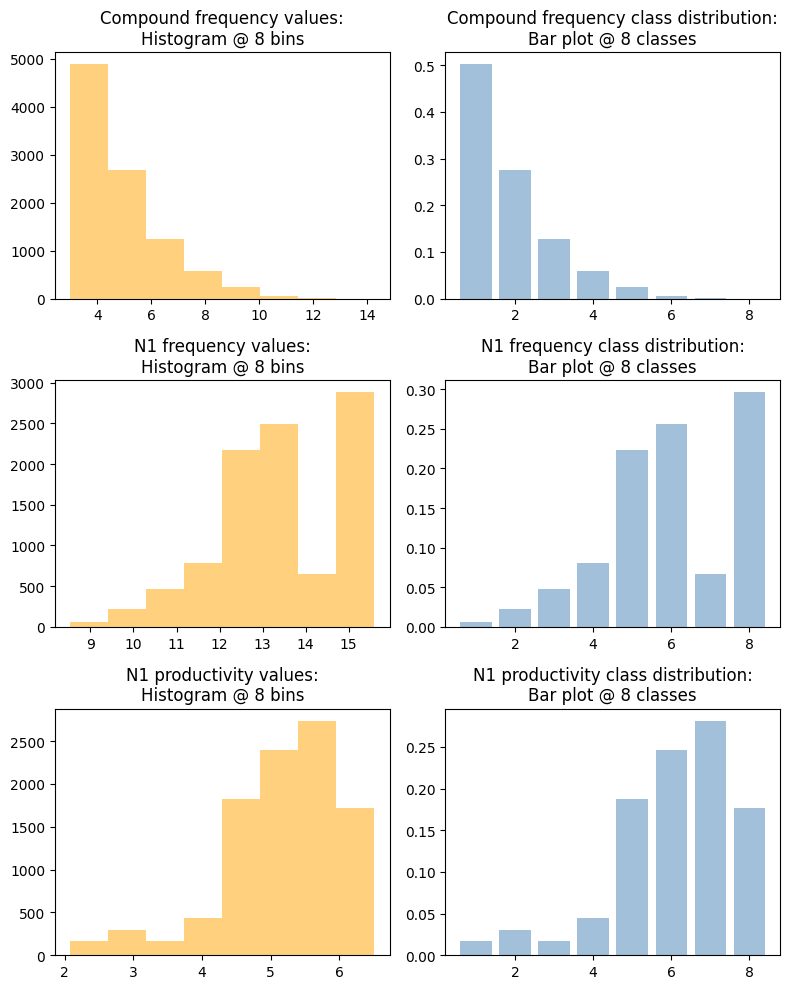

In [17]:
fig, axes = plt.subplots(3, 2, figsize=(8, 10))

all_param_shares = {}
for i, (param_name, title) in enumerate([
    ("comp_freq", "Compound frequency"),
    ("n1_freq", "N1 frequency"),
    ("n1_prod", "N1 productivity")
]):
    # log values
    axes[i, 0].hist(np.log(gecodb_v07pll[param_name]), bins=NCLASSES, color="orange", alpha=0.5)
    axes[i, 0].set_title(f"{title} values:\nHistogram @ {NCLASSES} bins")
    # class distr
    param_counts = np.unique_counts(gecodb_v07pll[f"{param_name}_cl"])
    param_shares = param_counts.counts / param_counts.counts.sum()
    axes[i, 1].bar(param_counts.values, param_shares, color="steelblue", alpha=0.5)
    axes[i, 1].set_title(f"{title} class distribution:\nBar plot @ {NCLASSES} classes")
    all_param_shares[param_name] = (param_counts.values, param_shares)

plt.tight_layout()
plt.show()

7. Sample up to 300 compounds pro PLL in a distribution-aware manner.
    
    Compute the probability of each unique frequency code and use it as a weight for the members of the corresponding compound group when sampling. 

    NB! While the distribution of each individual parameter is further divided between the values of the other two parameters, it is still preserved since the same distribution of these shards will be preserved in the sample, and then the information about the distribution of the parameter will be preserved through those. As a simplified example, let us imagine that the compound frequency class `2` takes up 20% of all compounds. The 20% are distributed between the other two parameters as follows: `2-3-4` makes 10% of all compounds, `2-4-4` -- 7%, `2-6-5` -- 2.5%, and `2-2-8` -- 0.5%. Since we will use the probabilities of these codes as weights, the final sample will feature ~10% of compounds of frequency class `2-3-4`, ~7% of `2-4-4`, ~2.5% of `2-6-5`, and ~0.5% of `2-2-8`. If we add those back together, we will see that compound frequency `2` will take up ~20% of compounds in the final sample, which is within the original distribution. Since the three codes are independent, each of the three parameters is decomposed and expressed through these three-place codes the same way.

In [18]:
# calculate prob of each frequency class; note that the prob
# is for individual frequency classes and not their compounds
gecodb_v07pll["freq_class_prob"] = 0.0
for code in gecodb_v07pll["freq_class_code"].unique():
    code_sample = gecodb_v07pll[gecodb_v07pll["freq_class_code"] == code].index
    gecodb_v07pll.loc[
        gecodb_v07pll[gecodb_v07pll["freq_class_code"] == code].index,
        "freq_class_prob"
    ] = len(code_sample) / len(gecodb_v07pll)

gecodb_v07pll.sample(10)

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq,comp_freq_cl,n1_freq_cl,n1_prod_cl,freq_class_code,freq_class_prob
comp_gecodb,,,,,,,,,,,,,,,
anlage_politik,Anlagepolitik,3190,anlage,1195984,287,_,False,False,politik,2320757,4,7,7,4-7-7,0.002466
weide_+n_hain,Weidenhain,62,weide,59179,182,_+n_,True,False,hain,43055,1,3,6,1-3-6,0.008118
gut_+=er_korridor,Güterkorridor,34,gut,425955,153,_+=er_,True,True,korridor,34312,1,6,6,1-6-6,0.042544
last_+en_kahn,Lastenkahn,159,last,351714,94,_+en_,True,False,kahn,140777,2,5,5,2-5-5,0.010996
kohle_stück,Kohlestück,406,kohle,174115,278,_,False,False,stück,2330343,3,5,7,3-5-7,0.011201
bett_+en_bedarf,Bettenbedarf,138,bett,378276,165,_+en_,True,False,bedarf,593132,2,5,6,2-5-6,0.017778
bild_rausch,Bildrausch,42,bild,3732418,672,_,False,False,rausch,112128,1,8,8,1-8-8,0.080464
anlage_+n_komplex,Anlagenkomplex,94,anlage,1195984,287,_+n_,True,False,komplex,75237,2,7,7,2-7-7,0.009352
geschenk_+e_korb,Geschenkekorb,102,geschenk,522191,141,_+e_,True,False,korb,141538,2,6,6,2-6-6,0.023841


In [19]:
rng = np.random.default_rng(579372518)

In [20]:
N_PRO_PLL = 300

all_pll_comps = []
for pll in plls:
    pll_n1s = gecodb_v07pll[
        # attention for 'Mausefalle'- and 'Sternenwiese'-like compounds
        gecodb_v07pll["is_pll"] &
        (gecodb_v07pll["linker"] == pll)
    ]["n1_lemma"].unique()
    pll_comps = gecodb_v07pll[gecodb_v07pll["n1_lemma"].isin(pll_n1s)]
    # normalize to sum up to 1
    pll_comps["freq_class_prob"] = (
        pll_comps["freq_class_prob"] / pll_comps["freq_class_prob"].sum()
    )
    if len(pll_comps) <= N_PRO_PLL:
        all_pll_comps.extend(pll_comps.index)
    else:
        pll_comps_sample = rng.choice(
            pll_comps.index,
            size=N_PRO_PLL,
            replace=False,  # prohibit repetitions
            p=pll_comps["freq_class_prob"]
        )
        all_pll_comps.extend(pll_comps_sample)

gecodb_v07pll_300er = gecodb_v07pll.loc[all_pll_comps]
gecodb_v07pll_300er.sample(10)

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq,comp_freq_cl,n1_freq_cl,n1_prod_cl,freq_class_code,freq_class_prob
comp_gecodb,,,,,,,,,,,,,,,
strahl_+en_arzt,Strahlenarzt,47,strahl,19771,134,_+en_,True,False,arzt,1440751,1,2,6,1-2-6,0.008324
bild_aufgabe,Bildaufgabe,37,bild,3732418,672,_,False,False,aufgabe,2213168,1,8,8,1-8-8,0.080464
geist_+=er_umzug,Geisterumzug,67,geist,480796,242,_+er_,True,False,umzug,480110,1,6,7,1-6-7,0.052102
buch_+=er_sommer,Büchersommer,107,buch,2731652,603,_+=er_,True,True,sommer,2090038,2,8,8,2-8-8,0.050252
einnahme_fehler,Einnahmefehler,50,einnahme,595736,120,_,False,False,fehler,1110672,1,6,5,1-6-5,0.032885
mitglied_stadt,Mitgliedstadt,51,mitglied,3723961,267,_,False,False,stadt,9376427,1,8,7,1-8-7,0.029288
gast_+=e_rückgang,Gästerückgang,275,gast,4687625,464,_+=e_,True,True,rückgang,383861,2,8,8,2-8-8,0.050252
vater_+=_sitte,Vätersitte,38,vater,2240091,98,_+=_,True,True,sitte,72000,1,7,5,1-7-5,0.009763
geburt_+en_klinik,Geburtenklinik,254,geburt,397076,199,_+en_,True,False,klinik,724764,2,5,6,2-5-6,0.017778


8. Manual cleaning.

    In this step, we manually remove the entries in the intermediate dataset that are misanalyses of similar. Many thanks to Reinhild Barkey for a thorough inspection of the intermediate dataset.

In [21]:
to_remove = [
    # Adverb
    "vater_los", "weg_los",
    # Derivation
    "weg_fahrer", "weg_läufer", "weg_transport", "weg_werfer", "weg_wurf",
    # Eigenname
    "gast_mann", "asche_meier", "baddeck", "bad_werk", "buch_hain", "buch_halt",
    "bett_rum", "bruder_müller", "henne_vogel", "lied_ecke", "vater_laus",
    "weg_schneider", "bad_städter", "weg_rat",
    # nominslisiertes Verb
    "weg_lese",
    # falsche Trennung
    "bad_egel",  # bad_e_gel
    "buch_+s_busch",    # buchs_busch
    "buch_+s_hecke",    # buchs_hecke
    "buch_+s_kranz",    # buchs_kranz
    # nominalisiertes Verb
    "weg_rennen", "weg_schlummer",
    # typo
    "gast_gerber",  # Gastgeber
    "weg_+e_fährte",    # Weggefährte
    "weg_+e_rand"   # Wegrand/Wegesrand
]

to_remove = [g for g in to_remove if g in gecodb_v07pll_300er.index]
gecodb_v07pll_300er.drop(to_remove, inplace=True)

9. Self-evaluation: make sure that the distribution of the linker and the frequency classes of the whole population is identical to that of the sample.

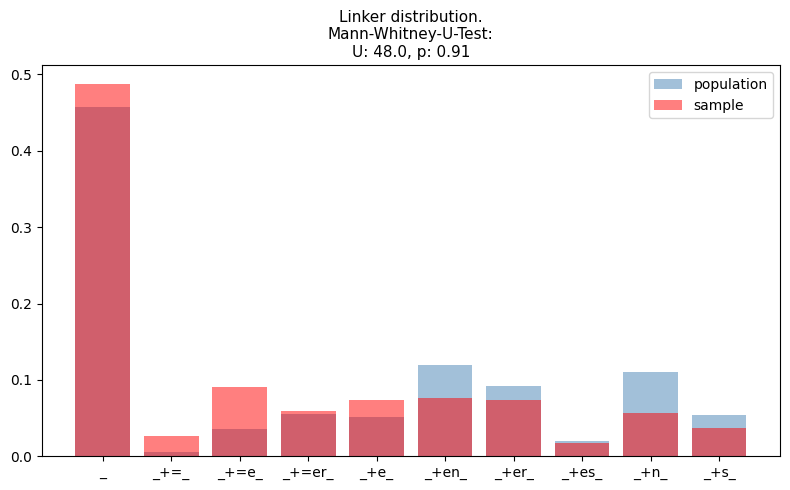

In [22]:
# check if the distribution of the linkers is identical
linker_counts = np.unique_counts(gecodb_v07pll["linker"])
linker_shares = linker_counts.counts / linker_counts.counts.sum()

linker_counts_300er = np.unique_counts(gecodb_v07pll_300er["linker"])
linker_shares_300er = linker_counts_300er.counts / linker_counts_300er.counts.sum()

_, ax = plt.subplots(figsize=(8, 5))
ax.bar(linker_counts.values, linker_shares, color="steelblue", alpha=0.5, label="population")
ax.bar(linker_counts_300er.values, linker_shares_300er, color="red", alpha=0.5, label="sample")
ax.legend()

# test for identical distributions;
# p > 0.05 => the distributions are identical
mwu = mannwhitneyu(linker_shares, linker_shares_300er)
plt.title(
    "Linker distribution.\n"
    "Mann-Whitney-U-Test:\n"
    f"U: {mwu.statistic}, p: {mwu.pvalue.round(3)}",
    fontsize=11
)
plt.tight_layout()
plt.savefig(
    os.path.join(sample_dir, "linker_distr.png"),
    format="png",
    dpi="figure"
)
plt.show()

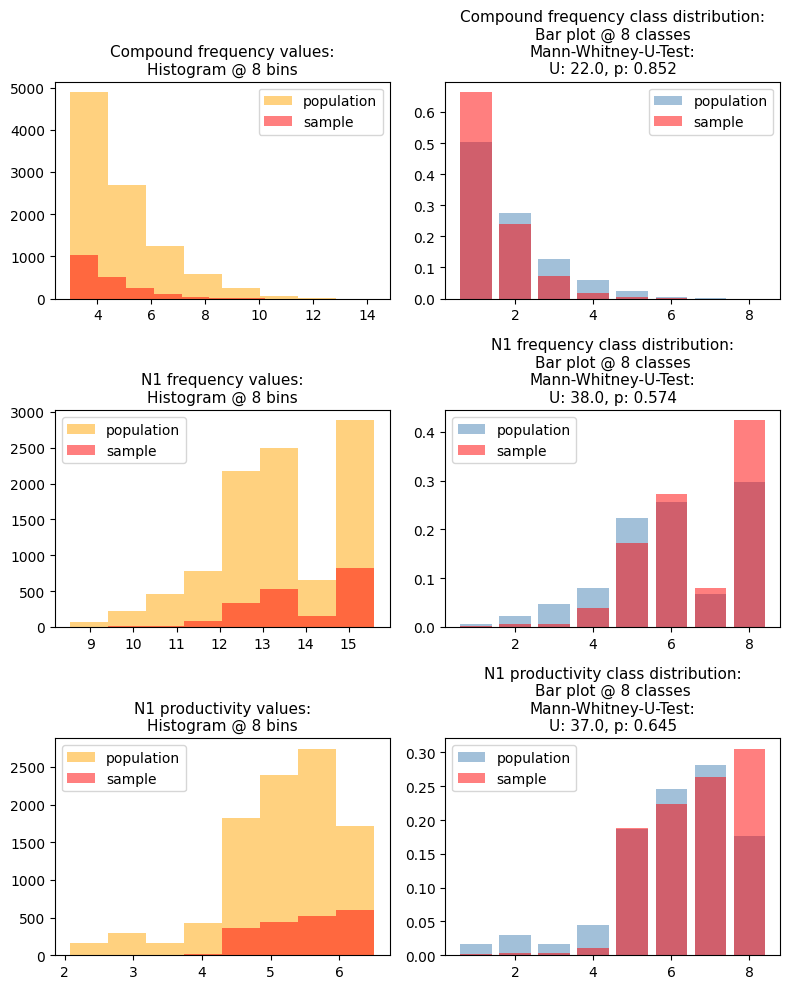

In [23]:
# show the distribution of individual parameter log values
# vs the frequency code probs: whole population & sample
fig, axes = plt.subplots(3, 2, figsize=(8, 10))

for i, (param_name, title) in enumerate([
    ("comp_freq", "Compound frequency"),
    ("n1_freq", "N1 frequency"),
    ("n1_prod", "N1 productivity")
]):
    # log values: population vs sample, respectively
    axes[i, 0].hist(np.log(gecodb_v07pll[param_name]), bins=NCLASSES, color="orange", alpha=0.5, label="population")
    axes[i, 0].hist(np.log(gecodb_v07pll_300er[param_name]), bins=NCLASSES, color="red", alpha=0.5, label="sample")
    
    axes[i, 0].set_title(f"{title} values:\nHistogram @ {NCLASSES} bins", fontsize=11)

    # class distr: population vs sample, respectively
    axes[i, 1].bar(*all_param_shares[param_name], color="steelblue", alpha=0.5, label="population")
    param_counts_300er = np.unique_counts(gecodb_v07pll_300er[f"{param_name}_cl"])
    param_shares_300er = param_counts_300er.counts / param_counts_300er.counts.sum()
    axes[i, 1].bar(param_counts_300er.values, param_shares_300er, color="red", alpha=0.5, label="sample")
    
    axes[i, 0].legend()
    axes[i, 1].legend()

    # test for identical distributions;
    # p > 0.05 => the distributions are identical
    mwu = mannwhitneyu(all_param_shares[param_name][1], param_shares_300er)
    axes[i, 1].set_title(
        f"{title} class distribution:\n"
        f"Bar plot @ {NCLASSES} classes\n"
        "Mann-Whitney-U-Test:\n"
        f"U: {mwu.statistic}, p: {mwu.pvalue.round(3)}",
        fontsize=11
    )

plt.tight_layout()
plt.savefig(
    os.path.join(sample_dir, "frequency_distrs.png"),
    format="png",
    dpi="figure"
)
plt.show()

In [24]:
# save intermediate sample
# (N=1954, PLL N=892, NPLL N=1062, UniqN1N=66)
gecodb_v07pll_300er.to_csv(
    os.path.join(sample_dir, "sample.tsv"),
    sep="\t",
    header=True,
    index=True
)

10. Extract contexts from DeReKo.

In [25]:
input_lemmata = gecodb_v07pll_300er["comp_lemma"].values.tolist()
matches = get_dereko_matches(input_lemmata, from_nb=True, nb_depth=1)

11. Format the dataset.

    We will be collection annotations concerning the singular/plural meaning of N1. We will have four categories:
    * Not countable / generic: 'Holzbrett', 'Pflegedienst', 'Buchhandel'
    * Unambiguously Sg: 'Buchdeckel', 'Landesbank'
    * Ambiguous: 'Kinderwagen', 'Zeitungsleser'
    * Unambiguously Pl: 'Blumenstrauß', 'Bücherregal'
    * None

    For the convenience of the annotators, we will prepare vignettes for them to fill in. Each vignette will consist of the compound entry and fields for marking the assigned category, a comment field, and three contexts.

In [ ]:
N_CONTX = 3

# TODO: separate contexts
vignette_template = """\
# {i}: {lemma}
Annotation:\t\t-- []\t\tSg []\t\tSg/Pl []\t\tPl []\t\t?? []
Bemerkung: hier einfügen
Kontext 1: {context_1}
Kontext 2: {context_2}
Kontext 3: {context_3}

========================================


"""

# TODO: deduplicate contexts
def make_vignette(lemma: str, i: int) -> str:
    contexts = matches.get(lemma, {})
    if not len(contexts):
        return
    elif len(contexts) > N_CONTX:
        contexts = rng.choice(contexts, N_CONTX, replace=False)
    contexts = {
        f"context_{j + 1}": f"... {c['lc']}{c['match']}{c['rc']} ..."
        for j, c in enumerate(contexts)
    }
    vignette = vignette_template.format(
        i=i,
        lemma=lemma,
        **contexts
    )
    return vignette

In [27]:
rng.shuffle(input_lemmata)
vignettes = []
i = 1
for lemma in input_lemmata:
    vignette = make_vignette(lemma, i)
    if not vignette:
        continue
    vignettes.append(vignette)
    i += 1

In [28]:
print(vignettes[345])

# 346: Generationenerfahrung
Annotation:		-- []		Sg []		Sg/Pl []		Pl []		?? []
Bemerkung: hier einfügen
Kontext 1: ... dies war bis in die 70er- und sogar 80er-Jahre hinein Normalität in westlichen Gesellschaften. Nicht in jedem Haushalt. Nicht in jeder Familie. Aber doch in hinreichend vielen, um eine Art Generationenerfahrung für die heute 50-Jährigen zu sein. Ebenso, wie es in Deutschland trotz aller Emanzipations- und Bildungsaufbrüche der 68er-Bewegung noch lange üblich war, dass die Frauen zu Hause blieben und sich ...
Kontext 2: ... der undogmatischen Linken, die Danquart und Fischer gleichermaßen teilen: Man guckte sich in die Augen und man vertraute sich. Nervtötendes Schwadronieren Für alle, die nicht dabei gewesen sind und diese Generationenerfahrung nicht teilen: Die Spontis waren jener Teil der auf die Studentenrevolte von 1968 zurückgehenden linken Bewegung, der, gleichermaßen antikapitalistisch wie antikommunistisch, die Befreiung des Subjekts und nicht irgendwelche obje

12. Save the dataset.

In [76]:
with open(
    os.path.join(sample_dir, "vignettes.txt"),
    "w",
    encoding="utf-8"
) as out:
    for vignette in vignettes:
        out.write(vignette)

In [29]:
# found matches for all compounds
i - 1 == len(input_lemmata)

True

Also save a subsample of 100 compounds for me to annotate myself to understand the data better and validate the adequacy of the proposed categories.

In [77]:
vignettes_100er = rng.choice(vignettes, 100, replace=False)
with open(
    os.path.join(sample_dir, "vignettes_100er.txt"),
    "w",
    encoding="utf-8"
) as out:
    for vignette in vignettes_100er:
        out.write(vignette)